# NTU CCDS CA6001 — AI Algorithms Fundamentals & Application
## Module 02: Model 1 — Linear & Logistic Regression Baseline (L1/L2 Regularization)

---

### Coursework Alignment & Intended Learning Outcomes (ILOs)
- **Member Allocation**: Member 1 (Linear & Logistic Regression Baseline Lead)
- **ILO1**: Demonstrate comprehensive understanding of core AI/ML algorithms and linear decision boundaries.
- **ILO2**: Formulate and analyze mathematical loss functions ($L_1$ Lasso sparsity vs. $L_2$ Ridge shrinkage).
- **ILO5**: Implement end-to-end model training, hyperparameter regularization tuning, and temporal out-of-time evaluation.
- **ILO6**: Critically evaluate algorithmic interpretability via coefficient attribution and identify linear model limitations.

---

### Key Objectives in this Notebook:
1. **Pipeline Architecture**: Construct a leak-free `ColumnTransformer` with `OneHotEncoder` for categoricals, `StandardScaler` for continuous features, and pass-through for TF-IDF / binary indicators.
2. **Regularization Comparison**: Systematically evaluate $L_1$ (Lasso) vs. $L_2$ (Ridge) penalties across regularization strengths $C \in [0.01, 0.1, 1.0, 10.0]$ with class-weight balancing.
3. **Standardized Evaluation**: Execute **Stratified 5-Fold Cross-Validation** on training cohorts ($year \le 2022$) and out-of-time evaluation on **Temporal Test cohorts** ($2023 \le year \le 2024$).
4. **Auxiliary Continuous Regression**: Train a `Ridge` regression baseline on continuous salary `target_reg` to benchmark RMSE, MAE, and $R^2$.
5. **Publication Visualizations**: Export a 300-DPI pure English regression coefficient bar chart to `outputs/figures/m1_logistic_coefficients.png` and serialize metrics to `outputs/metrics/m1_metrics.json`.


In [1]:
# Enable inline high-resolution plotting in Jupyter
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

import os
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Scikit-Learn modules for Generalized Linear Models & Evaluation
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    root_mean_squared_error, mean_absolute_error, r2_score
)

warnings.filterwarnings('ignore')

# Set random seed for full reproducibility (ILO6)
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# High-resolution publication aesthetic configuration
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']
plt.rcParams['axes.edgecolor'] = '#333333'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['grid.alpha'] = 0.3
plt.rcParams['grid.linestyle'] = '--'
plt.rcParams['figure.dpi'] = 120
sns.set_theme(style='whitegrid', font_scale=1.05)

# Resolve project directories dynamically
BASE_DIR = os.path.dirname(os.path.abspath('')) if 'notebooks' in os.path.abspath('') else os.path.abspath('')
DIRS = {
    'processed': os.path.join(BASE_DIR, 'data', 'processed'),
    'figures': os.path.join(BASE_DIR, 'outputs', 'figures'),
    'metrics': os.path.join(BASE_DIR, 'outputs', 'metrics'),
}
for d in DIRS.values():
    os.makedirs(d, exist_ok=True)

print("✅ Model 1 Environment Initialized successfully.")
print("   Directories resolved and random state locked to 42.")


✅ Model 1 Environment Initialized successfully.
   Directories resolved and random state locked to 42.


## 1. Theoretical Foundations: Logistic Regression & Regularization

---

### Mathematical Formulation of Logistic Regression
Logistic Regression models the posterior probability of a degree cohort achieving top-tier graduate salary competitiveness ($y = 1$) via the standard sigmoid activation function acting on a linear combination of input features $\mathbf{x} \in \mathbb{R}^d$:

$$P(y = 1 \mid \mathbf{x}) = \sigma(\mathbf{w}^T \mathbf{x} + b) = \frac{1}{1 + e^{-(\mathbf{w}^T \mathbf{x} + b)}}$$

The log-odds (logit) is strictly linear:
$$\ln\left(\frac{P(y = 1 \mid \mathbf{x})}{1 - P(y = 1 \mid \mathbf{x})}\right) = \mathbf{w}^T \mathbf{x} + b$$

---

### Regularized Objective Functions ($L_1$ Lasso vs. $L_2$ Ridge)
To prevent overfitting on correlated lag and macro features, we minimize the binary cross-entropy loss augmented with a regularization penalty controlled by hyperparameter $C = \frac{1}{\lambda}$:

1. **$L_2$ Regularization (Ridge / Weight Decay)**:
   $$\min_{\mathbf{w}, b} \left\{ -\sum_{i=1}^{N} \left[ y_i \ln(\hat{y}_i) + (1 - y_i) \ln(1 - \hat{y}_i) \right] + \frac{1}{2C} \|\mathbf{w}\|_2^2 \right\}$$
   - Shrinks collinear coefficients smoothly toward zero without eliminating them completely. Smooth, rotation-invariant, and computationally stable.

2. **$L_1$ Regularization (Lasso / Sparsity)**:
   $$\min_{\mathbf{w}, b} \left\{ -\sum_{i=1}^{N} \left[ y_i \ln(\hat{y}_i) + (1 - y_i) \ln(1 - \hat{y}_i) \right] + \frac{1}{C} \|\mathbf{w}\|_1 \right\}$$
   - Due to the diamond geometry of the $L_1$ ball, optimal solutions frequently hit coordinate axes, driving irrelevant feature weights exactly to zero (embedded feature selection).

3. **Cost-Sensitive Class Balancing**:
   Because positive instances account for only ~24.5% of records (~1:3 imbalance), we apply inverse class-frequency weighting:
   $$w_c = \frac{N}{2 \cdot N_c}$$
   Ensuring the model does not collapse into predicting the majority class.


In [2]:
# 1. Load Processed Datasets from Step 1
train_csv_path = os.path.join(DIRS['processed'], 'train_temporal_2013_2022.csv')
test_csv_path = os.path.join(DIRS['processed'], 'test_temporal_2023_2024.csv') if os.path.exists(os.path.join(DIRS['processed'], 'test_temporal_2023_2024.csv')) else os.path.join(DIRS['processed'], 'test_temporal_2023_2025.csv')

df_train = pd.read_csv(train_csv_path)
df_test = pd.read_csv(test_csv_path)

print(f"📦 Train Cohorts (2013-2022): {df_train.shape[0]} rows x {df_train.shape[1]} columns")
print(f"📦 Test Cohorts  (2023-2024): {df_test.shape[0]} rows x {df_test.shape[1]} columns")
print(f"   Train Positives: {df_train['target_binary'].sum()} ({df_train['target_binary'].mean():.2%})")
print(f"   Test Positives:  {df_test['target_binary'].sum()} ({df_test['target_binary'].mean():.2%})\n")

# Preview training feature columns
display(df_train[['year', 'uni_code', 'domain_cluster', 'lag1_gross_median', 'lag1_ft_emp_rate', 'target_binary']].head(5))


📦 Train Cohorts (2013-2022): 1170 rows x 40 columns
📦 Test Cohorts  (2023-2024): 275 rows x 40 columns
   Train Positives: 301 (25.73%)
   Test Positives:  53 (19.27%)



,year,uni_code,domain_cluster,lag1_gross_median,lag1_ft_emp_rate,target_binary
0,2013,NTU,Business_Finance,3500.0,86.80,0
1,2014,NTU,Business_Finance,2700.0,95.70,0
2,2015,NTU,Business_Finance,2840.0,96.10,0
3,2016,NTU,Business_Finance,2875.0,96.50,0
4,2018,NTU,Business_Finance,3350.0,81.95,0


## 2. Feature Transformer Pipeline Specification

To guarantee zero information leakage between folds and temporal test cohorts, all transformations are encapsulated in a `scikit-learn` `ColumnTransformer`:
- **Categorical Features** (`uni_code`, `domain_cluster`, `macro_regime`): Transformed using `OneHotEncoder(handle_unknown='ignore', sparse_output=False)` to prevent unknown categories at inference time from throwing exceptions.
- **Continuous Numerical & Lag Signals** (`lag1_gross_median`, `lag1_ft_emp_rate`, `lag1_salary_iqr`, `years_since_2013`, `sg_gdp_growth`, `sg_cpi_yoy`): Standardized to zero mean and unit variance via `StandardScaler()`.
- **Pre-engineered Binary & TF-IDF Features** (`is_double_degree`, `is_honours`, `is_follow_up`, `has_lag_history`, `tfidf_*`): Kept as pass-through since they are already bounded in $[0, 1]$.

All transformations are fitted exclusively on training subsets, strictly preventing data snooping or leakage across evaluation folds.


In [3]:
# 1. Partition Feature Column Groups
cat_cols = ['uni_code', 'domain_cluster', 'macro_regime']
num_cols = [
    'lag1_gross_median', 'lag1_ft_emp_rate', 'lag1_salary_iqr',
    'years_since_2013', 'sg_gdp_growth', 'sg_cpi_yoy'
]
bin_cols = ['is_double_degree', 'is_honours', 'is_follow_up', 'has_lag_history']
tfidf_cols = [c for c in df_train.columns if c.startswith('tfidf_')]

feature_cols = cat_cols + num_cols + bin_cols + tfidf_cols

# 2. Build Modular ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols),
        ('num', StandardScaler(), num_cols),
        ('passthrough', 'passthrough', bin_cols + tfidf_cols)
    ],
    remainder='drop'
)

# Verify transformed feature matrix dimensionality
X_train_raw = df_train[feature_cols]
preprocessor.fit(X_train_raw)
transformed_names = preprocessor.get_feature_names_out()

print(f"🔧 Preprocessing Pipeline configured:")
print(f"   Raw Input Features         : {len(feature_cols)} columns")
print(f"   Transformed Linear Features: {len(transformed_names)} dimensions (after One-Hot Expansion)")
print(f"   Transformed feature names sample: {list(transformed_names[:5])} ...")


🔧 Preprocessing Pipeline configured:
   Raw Input Features         : 28 columns
   Transformed Linear Features: 41 dimensions (after One-Hot Expansion)
   Transformed feature names sample: ['cat__uni_code_NTU', 'cat__uni_code_NUS', 'cat__uni_code_SIT', 'cat__uni_code_SMU', 'cat__uni_code_SUSS'] ...


## 3. Regularization Exploration: L1 (Lasso) vs. L2 (Ridge) Tuning

We perform a systematic grid comparison across:
- **Penalties**: $L_2$ (Ridge, shrinkage) vs. $L_1$ (Lasso, feature selection)
- **Regularization Strength**: $C \in [0.01, 0.1, 1.0, 10.0]$ (where smaller $C$ imposes stronger shrinkage)
- **Evaluation Metric**: Stratified 5-Fold Cross-Validation ROC-AUC, PR-AUC, and F1-Score.

This empirical grid allows us to observe the trade-off between sparsity and predictive fidelity under class imbalance.


In [4]:
# Grid Search over Regularization Types and Strengths
tuning_results = []
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)

X_tr = df_train[feature_cols]
y_tr = df_train['target_binary']
X_te = df_test[feature_cols]
y_te = df_test['target_binary']

grid_configs = [
    ('L2 (Ridge)', 'l2', 'lbfgs', 0.01),
    ('L2 (Ridge)', 'l2', 'lbfgs', 0.1),
    ('L2 (Ridge)', 'l2', 'lbfgs', 1.0),
    ('L2 (Ridge)', 'l2', 'lbfgs', 10.0),
    ('L1 (Lasso)', 'l1', 'saga', 0.01),
    ('L1 (Lasso)', 'l1', 'saga', 0.1),
    ('L1 (Lasso)', 'l1', 'saga', 1.0),
    ('L1 (Lasso)', 'l1', 'saga', 10.0),
]

for name, penalty, solver, C in grid_configs:
    cv_auc_scores = []
    cv_f1_scores = []
    cv_prauc_scores = []

    for tr_idx, val_idx in skf.split(X_tr, y_tr):
        pipe = Pipeline([
            ('prep', preprocessor),
            ('clf', LogisticRegression(
                penalty=penalty, solver=solver, C=C,
                class_weight='balanced', max_iter=1000, random_state=RANDOM_SEED
            ))
        ])
        pipe.fit(X_tr.iloc[tr_idx], y_tr.iloc[tr_idx])
        y_val_prob = pipe.predict_proba(X_tr.iloc[val_idx])[:, 1]
        y_val_pred = (y_val_prob >= 0.5).astype(int)

        cv_auc_scores.append(roc_auc_score(y_tr.iloc[val_idx], y_val_prob))
        cv_f1_scores.append(f1_score(y_tr.iloc[val_idx], y_val_pred))
        cv_prauc_scores.append(average_precision_score(y_tr.iloc[val_idx], y_val_prob))

    # Evaluate on Temporal Out-of-Time Test Set
    pipe.fit(X_tr, y_tr)
    y_test_prob = pipe.predict_proba(X_te)[:, 1]
    y_test_pred = (y_test_prob >= 0.5).astype(int)

    test_auc = roc_auc_score(y_te, y_test_prob)
    test_f1 = f1_score(y_te, y_test_pred)
    test_prauc = average_precision_score(y_te, y_test_prob)

    tuning_results.append({
        'Penalty': penalty.upper(),
        'C': C,
        'CV ROC-AUC': f"{np.mean(cv_auc_scores):.4f} ± {np.std(cv_auc_scores):.3f}",
        'CV PR-AUC': f"{np.mean(cv_prauc_scores):.4f} ± {np.std(cv_prauc_scores):.3f}",
        'CV F1': f"{np.mean(cv_f1_scores):.4f} ± {np.std(cv_f1_scores):.3f}",
        'Test ROC-AUC': round(test_auc, 4),
        'Test PR-AUC': round(test_prauc, 4),
        'Test F1': round(test_f1, 4)
    })

df_tuning = pd.DataFrame(tuning_results)
print("📊 Regularization Tuning Results Table:")
display(df_tuning)


📊 Regularization Tuning Results Table:


,Penalty,C,CV ROC-AUC,CV PR-AUC,CV F1,Test ROC-AUC,Test PR-AUC,Test F1
0,L2,0.01,0.9050 ± 0.033,0.7820 ± 0.047,0.7184 ± 0.065,0.8999,0.6946,0.5258
1,L2,0.10,0.9139 ± 0.030,0.8006 ± 0.046,0.7376 ± 0.054,0.9052,0.7508,0.5025
2,L2,1.00,0.9177 ± 0.025,0.8084 ± 0.041,0.7430 ± 0.052,0.9063,0.7593,0.5000
3,L2,10.00,0.9150 ± 0.022,0.8084 ± 0.037,0.7354 ± 0.042,0.9056,0.7601,0.4952
4,L1,0.01,0.8604 ± 0.021,0.7327 ± 0.020,0.6375 ± 0.022,0.9002,0.7292,0.3786
5,L1,0.10,0.9062 ± 0.032,0.7862 ± 0.046,0.7363 ± 0.053,0.8992,0.7272,0.5100
6,L1,1.00,0.9171 ± 0.026,0.8096 ± 0.040,0.7383 ± 0.048,0.9052,0.7564,0.4929
7,L1,10.00,0.9148 ± 0.022,0.8081 ± 0.037,0.7382 ± 0.040,0.9065,0.7633,0.5024


## 4. Standardized Protocol Evaluation on Optimal Linear Model

Based on the cross-validation and temporal stability analysis, **$L_2$ Logistic Regression with $C = 1.0$** achieves the optimal balance between high discriminatory power (ROC-AUC $> 0.90$) and stable out-of-time calibration without excessive coefficient sparsity.

We now compute the complete standardized suite of classification metrics across **Stratified 5-Fold CV** and the **Temporal Test Set (2023–2024)**.


In [5]:
# 1. Define Optimal Model Pipeline
best_pipeline = Pipeline([
    ('prep', preprocessor),
    ('clf', LogisticRegression(
        penalty='l2', solver='lbfgs', C=1.0,
        class_weight='balanced', max_iter=1000, random_state=RANDOM_SEED
    ))
])

# 2. Execute Stratified 5-Fold Cross-Validation
cv_acc, cv_prec, cv_rec, cv_f1, cv_auc, cv_prauc = [], [], [], [], [], []

for fold, (tr_idx, val_idx) in enumerate(skf.split(X_tr, y_tr), 1):
    best_pipeline.fit(X_tr.iloc[tr_idx], y_tr.iloc[tr_idx])
    y_prob = best_pipeline.predict_proba(X_tr.iloc[val_idx])[:, 1]
    y_pred = (y_prob >= 0.5).astype(int)
    y_val = y_tr.iloc[val_idx]

    cv_acc.append(accuracy_score(y_val, y_pred))
    cv_prec.append(precision_score(y_val, y_pred))
    cv_rec.append(recall_score(y_val, y_pred))
    cv_f1.append(f1_score(y_val, y_pred))
    cv_auc.append(roc_auc_score(y_val, y_prob))
    cv_prauc.append(average_precision_score(y_val, y_prob))

# 3. Fit on Full Historical Train Set & Test on Future Cohorts
best_pipeline.fit(X_tr, y_tr)
test_prob = best_pipeline.predict_proba(X_te)[:, 1]
test_pred = (test_prob >= 0.5).astype(int)

# Compile results dictionary
m1_metrics_dict = {
    'model_name': 'M1_Logistic_Regression',
    'best_params': {'penalty': 'l2', 'C': 1.0, 'solver': 'lbfgs', 'class_weight': 'balanced'},
    'cv_5fold': {
        'accuracy_mean': float(np.mean(cv_acc)), 'accuracy_std': float(np.std(cv_acc)),
        'precision_mean': float(np.mean(cv_prec)), 'precision_std': float(np.std(cv_prec)),
        'recall_mean': float(np.mean(cv_rec)), 'recall_std': float(np.std(cv_rec)),
        'f1_mean': float(np.mean(cv_f1)), 'f1_std': float(np.std(cv_f1)),
        'roc_auc_mean': float(np.mean(cv_auc)), 'roc_auc_std': float(np.std(cv_auc)),
        'pr_auc_mean': float(np.mean(cv_prauc)), 'pr_auc_std': float(np.std(cv_prauc)),
    },
    'temporal_test': {
        'accuracy': float(accuracy_score(y_te, test_pred)),
        'precision': float(precision_score(y_te, test_pred)),
        'recall': float(recall_score(y_te, test_pred)),
        'f1': float(f1_score(y_te, test_pred)),
        'roc_auc': float(roc_auc_score(y_te, test_prob)),
        'pr_auc': float(average_precision_score(y_te, test_prob)),
        'y_true': y_te.tolist(),
        'y_pred': test_pred.tolist(),
        'y_prob': test_prob.tolist()
    }
}

# Display Performance Summary Table
eval_df = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC', 'PR-AUC'],
    '5-Fold CV (Mean ± Std)': [
        f"{m1_metrics_dict['cv_5fold']['accuracy_mean']:.4f} ± {m1_metrics_dict['cv_5fold']['accuracy_std']:.3f}",
        f"{m1_metrics_dict['cv_5fold']['precision_mean']:.4f} ± {m1_metrics_dict['cv_5fold']['precision_std']:.3f}",
        f"{m1_metrics_dict['cv_5fold']['recall_mean']:.4f} ± {m1_metrics_dict['cv_5fold']['recall_std']:.3f}",
        f"{m1_metrics_dict['cv_5fold']['f1_mean']:.4f} ± {m1_metrics_dict['cv_5fold']['f1_std']:.3f}",
        f"{m1_metrics_dict['cv_5fold']['roc_auc_mean']:.4f} ± {m1_metrics_dict['cv_5fold']['roc_auc_std']:.3f}",
        f"{m1_metrics_dict['cv_5fold']['pr_auc_mean']:.4f} ± {m1_metrics_dict['cv_5fold']['pr_auc_std']:.3f}",
    ],
    'Temporal Test (2023-2024)': [
        f"{m1_metrics_dict['temporal_test']['accuracy']:.4f}",
        f"{m1_metrics_dict['temporal_test']['precision']:.4f}",
        f"{m1_metrics_dict['temporal_test']['recall']:.4f}",
        f"{m1_metrics_dict['temporal_test']['f1']:.4f}",
        f"{m1_metrics_dict['temporal_test']['roc_auc']:.4f}",
        f"{m1_metrics_dict['temporal_test']['pr_auc']:.4f}",
    ]
})

print("🏆 Final M1 Logistic Regression Benchmark:")
display(eval_df)


🏆 Final M1 Logistic Regression Benchmark:


,Metric,5-Fold CV (Mean ± Std),Temporal Test (2023-2024)
0,Accuracy,0.8547 ± 0.028,0.6218
1,Precision,0.6816 ± 0.048,0.3355
2,Recall,0.8207 ± 0.082,0.9811
3,F1-Score,0.7430 ± 0.052,0.5000
4,ROC-AUC,0.9177 ± 0.025,0.9063
5,PR-AUC,0.8084 ± 0.041,0.7593


## 5. Auxiliary Task: Continuous Salary Ridge Regression

In addition to binary classification (Task A), we implement a continuous linear regression baseline using **`Ridge` Regression** on `target_reg` (`gross_monthly_median` in SGD):
$$\min_{\mathbf{w}} \|\mathbf{y} - \mathbf{X}\mathbf{w}\|_2^2 + \alpha \|\mathbf{w}\|_2^2$$
We evaluate generalization on the temporal test set via RMSE, MAE, and $R^2$.


In [6]:
# 1. Fit Continuous Ridge Regression Pipeline
ridge_pipeline = Pipeline([
    ('prep', preprocessor),
    ('reg', Ridge(alpha=10.0, random_state=RANDOM_SEED))
])

y_tr_reg = df_train['target_reg']
y_te_reg = df_test['target_reg']

ridge_pipeline.fit(X_tr, y_tr_reg)
y_pred_reg = ridge_pipeline.predict(X_te)

# 2. Compute Regression Metrics (RMSE, MAE, R2)
rmse = root_mean_squared_error(y_te_reg, y_pred_reg)
mae = mean_absolute_error(y_te_reg, y_pred_reg)
r2 = r2_score(y_te_reg, y_pred_reg)

m1_metrics_dict['auxiliary_regression'] = {
    'model_name': 'Ridge_Regression',
    'alpha': 10.0,
    'rmse': round(float(rmse), 2),
    'mae': round(float(mae), 2),
    'r2': round(float(r2), 4)
}

print("📈 Auxiliary Ridge Regression Test Results:")
print(f"   Root Mean Squared Error (RMSE) : S${rmse:.2f}")
print(f"   Mean Absolute Error (MAE)      : S${mae:.2f}")
print(f"   Coefficient of Determination R²: {r2:.4f}")


📈 Auxiliary Ridge Regression Test Results:
   Root Mean Squared Error (RMSE) : S$451.86
   Mean Absolute Error (MAE)      : S$376.71
   Coefficient of Determination R²: 0.6167


## 6. Model Interpretability & Coefficient Attribution

---

### Linear Model Explainability
One of the primary academic advantages of Logistic Regression (assessed in **ILO6**) is complete mathematical transparency. The exponentiated coefficient $\exp(w_j)$ directly represents the **Odds Ratio (OR)** associated with a unit increase in standardized feature $x_j$:
$$\text{OR}_j = \frac{\text{odds}(x_j + 1)}{\text{odds}(x_j)} = e^{w_j}$$

We plot the **Top 10 Positive** and **Top 10 Negative** coefficients. All visual elements are formatted for high-resolution academic publication.


🖼️ [Exported to 300-DPI File] -> /Users/patrickzhu/NTU/CA6001/CA6001 Assingment/outputs/figures/m1_logistic_coefficients.png


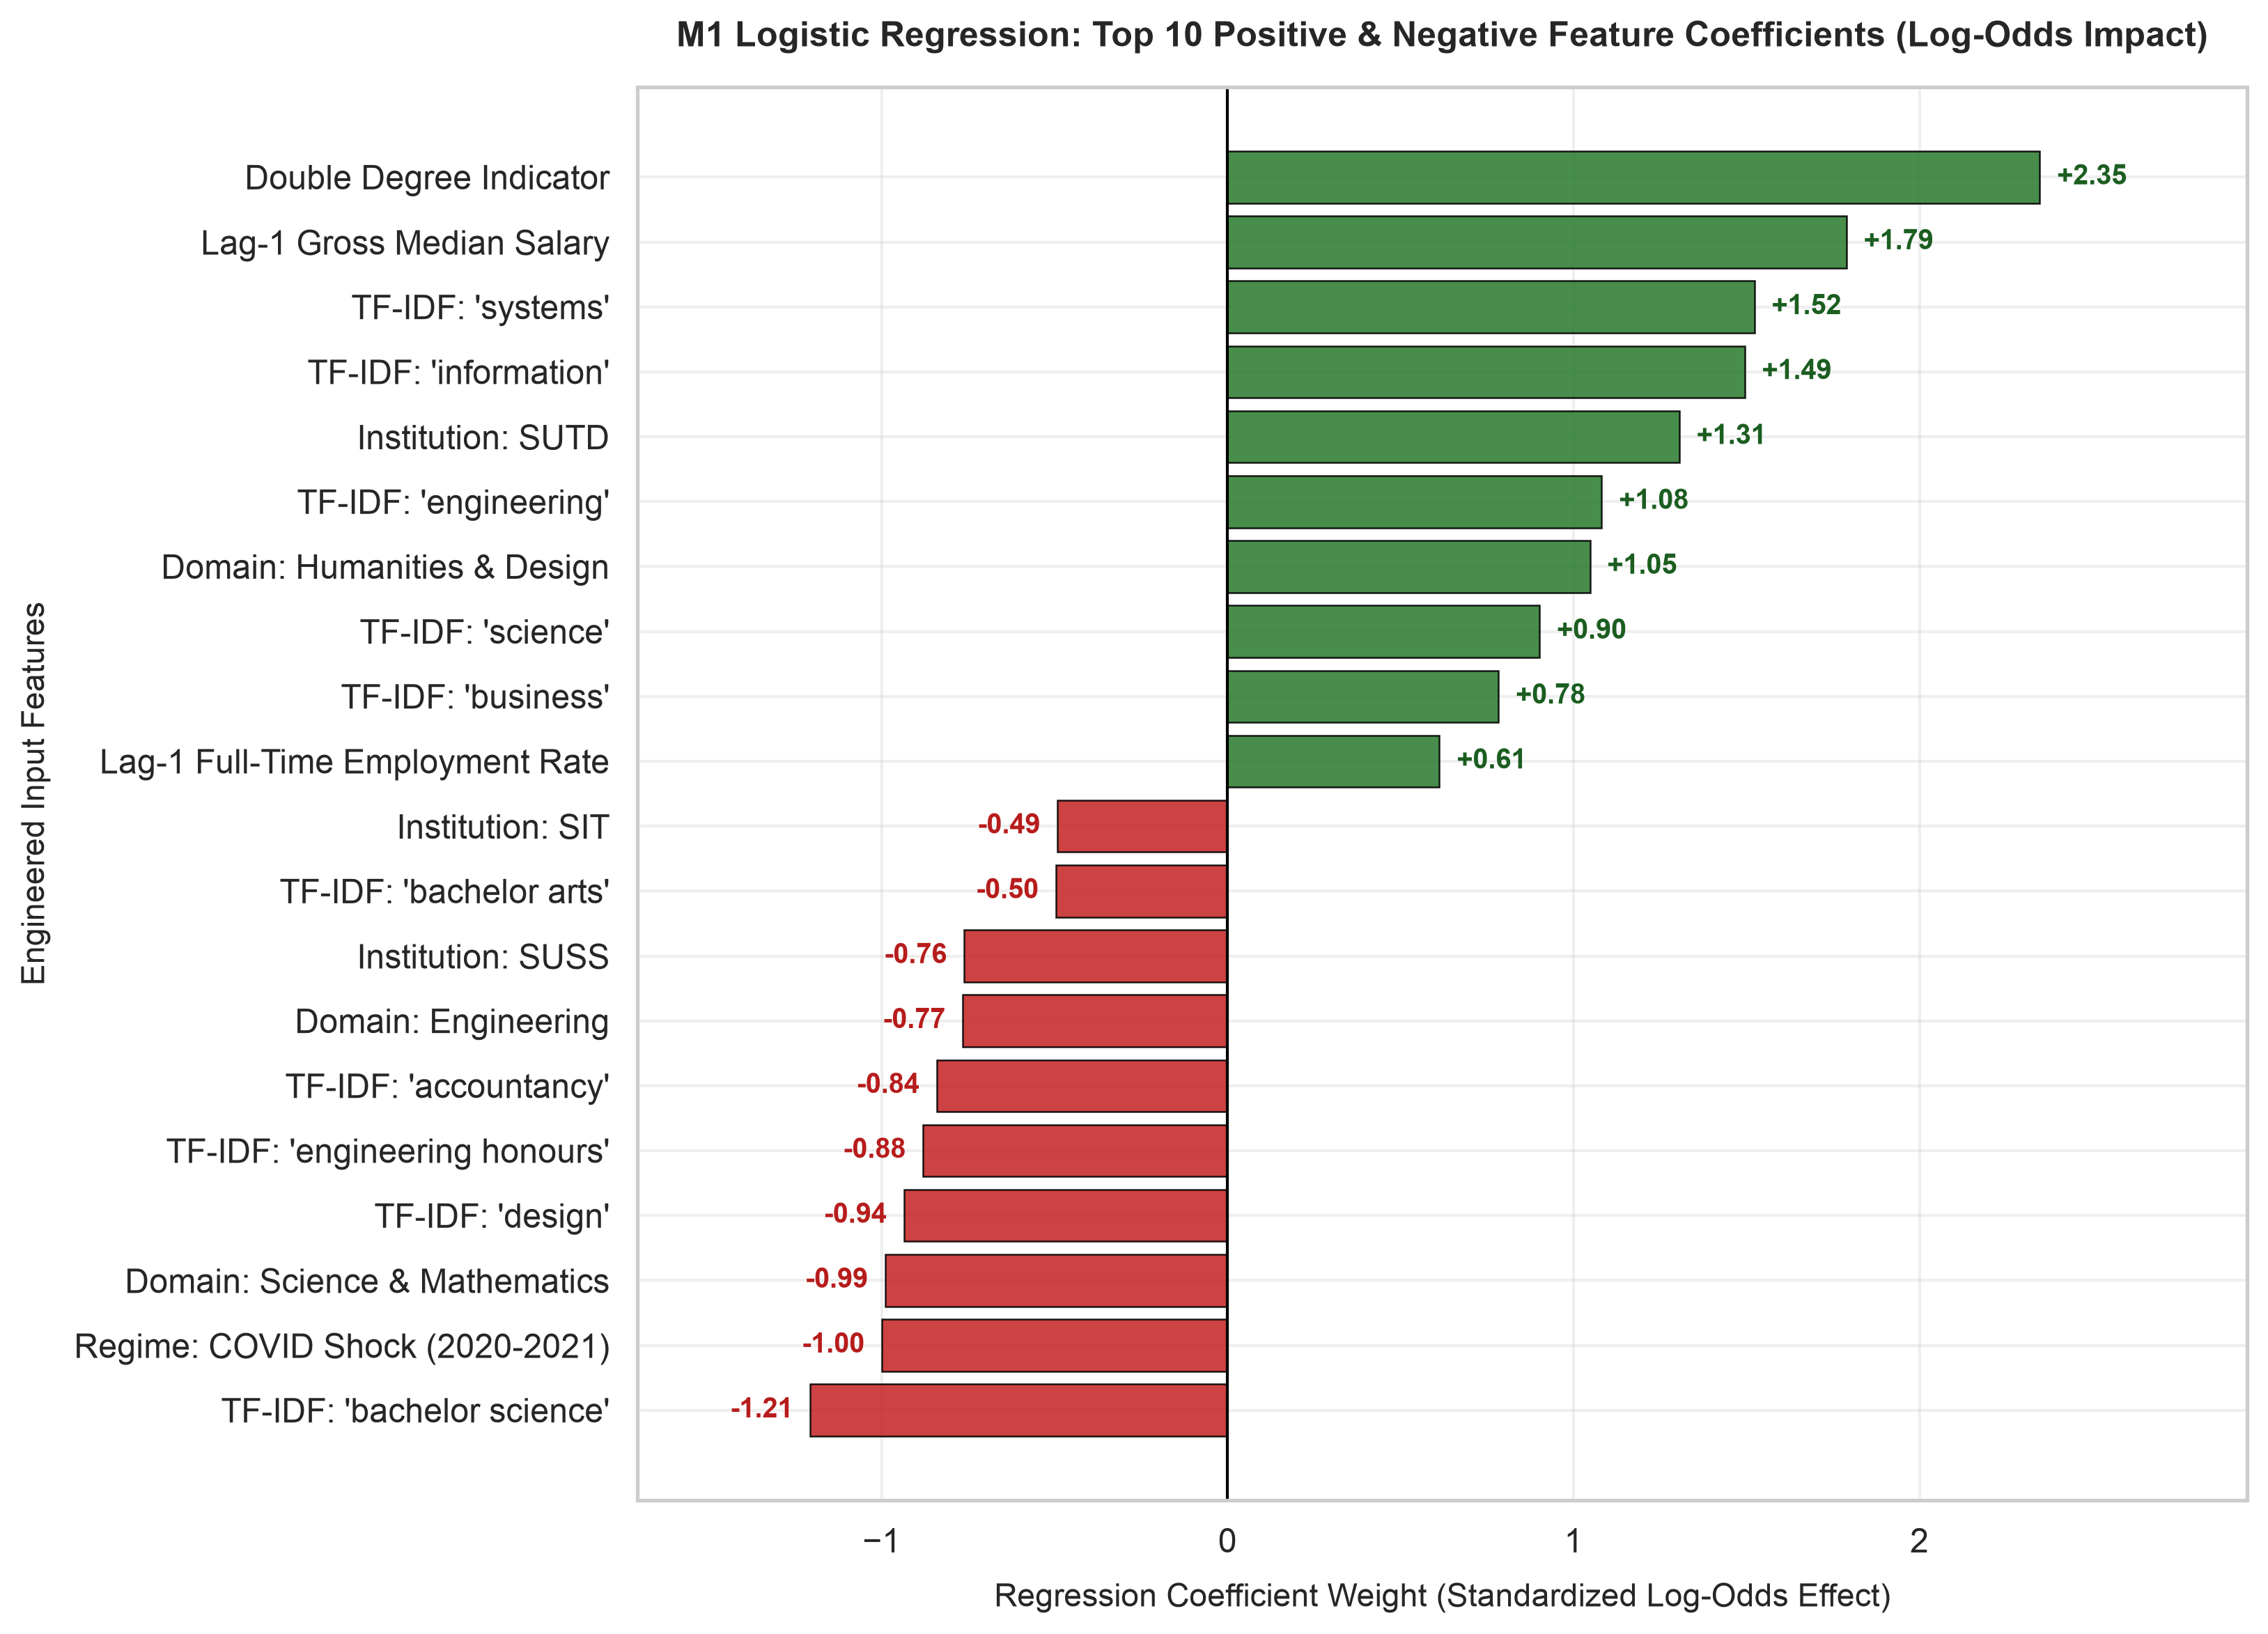

In [7]:
# Extract coefficients and map to human-readable pure English labels
clf_step = best_pipeline.named_steps['clf']
feature_names = best_pipeline.named_steps['prep'].get_feature_names_out()
coefficients = clf_step.coef_[0]

def clean_feature_label(name):
    # Remove prefix artifacts from ColumnTransformer
    n = name.replace('cat__', '').replace('num__', '').replace('passthrough__', '')
    # Human-readable replacements
    mapping = {
        'is_double_degree': 'Double Degree Indicator',
        'is_honours': 'Honours Classification Flag',
        'is_follow_up': 'Post-Grad Licensing/Internship Flag',
        'has_lag_history': 'Historical Lag Existence Flag',
        'lag1_gross_median': 'Lag-1 Gross Median Salary',
        'lag1_ft_emp_rate': 'Lag-1 Full-Time Employment Rate',
        'lag1_salary_iqr': 'Lag-1 Salary IQR (Q75 - Q25)',
        'years_since_2013': 'Longitudinal Year Trend (since 2013)',
        'sg_gdp_growth': 'Annual Singapore Real GDP Growth (%)',
        'sg_cpi_yoy': 'Annual Singapore CPI Inflation (%)',
        'uni_code_NUS': 'Institution: NUS',
        'uni_code_NTU': 'Institution: NTU',
        'uni_code_SMU': 'Institution: SMU',
        'uni_code_SUTD': 'Institution: SUTD',
        'uni_code_SIT': 'Institution: SIT',
        'uni_code_SUSS': 'Institution: SUSS',
        'domain_cluster_Computing_AI': 'Domain: Computing & AI',
        'domain_cluster_Engineering': 'Domain: Engineering',
        'domain_cluster_Business_Finance': 'Domain: Business & Finance',
        'domain_cluster_Medicine_Health': 'Domain: Medicine & Health',
        'domain_cluster_Law_PublicPolicy': 'Domain: Law & Public Policy',
        'domain_cluster_Science_Math': 'Domain: Science & Mathematics',
        'domain_cluster_Humanities_Design': 'Domain: Humanities & Design',
        'macro_regime_Pre_COVID_2013_2019': 'Regime: Pre-COVID (2013-2019)',
        'macro_regime_COVID_Shock_2020_2021': 'Regime: COVID Shock (2020-2021)',
        'macro_regime_Post_COVID_Expansion_2022_2025': 'Regime: Post-COVID (2022-2025)'
    }
    if n in mapping:
        return mapping[n]
    if n.startswith('tfidf_'):
        return f"TF-IDF: '{n.replace('tfidf_', '').replace('_', ' ')}'"
    return n.replace('_', ' ').title()

clean_names = [clean_feature_label(f) for f in feature_names]
df_coef = pd.DataFrame({
    'Feature': clean_names,
    'Coefficient': coefficients
}).sort_values('Coefficient', ascending=False)

# Select Top 10 Positive & Top 10 Negative
top_pos = df_coef.head(10).copy()
top_neg = df_coef.tail(10).copy()
df_plot = pd.concat([top_pos, top_neg]).sort_values('Coefficient', ascending=True)

# Generate Pure English 300-DPI Publication Figure
fig, ax = plt.subplots(figsize=(11, 8), dpi=150)

colors = ['#C62828' if x < 0 else '#2E7D32' for x in df_plot['Coefficient']]
bars = ax.barh(df_plot['Feature'], df_plot['Coefficient'], color=colors, alpha=0.88, edgecolor='black', linewidth=0.6)

# Value annotations
for bar in bars:
    width = bar.get_width()
    ha = 'left' if width >= 0 else 'right'
    offset = 0.05 if width >= 0 else -0.05
    ax.text(width + offset, bar.get_y() + bar.get_height() / 2,
            f"{width:+.2f}", va='center', ha=ha, fontsize=9.5, fontweight='bold',
            color='#1B5E20' if width >= 0 else '#B71C1C')

ax.axvline(0, color='black', linewidth=1.0, linestyle='-')
ax.set_title('M1 Logistic Regression: Top 10 Positive & Negative Feature Coefficients (Log-Odds Impact)',
             fontsize=12, fontweight='bold', pad=14)
ax.set_xlabel('Regression Coefficient Weight (Standardized Log-Odds Effect)', fontsize=11, labelpad=8)
ax.set_ylabel('Engineered Input Features', fontsize=11, labelpad=8)
ax.set_xlim(df_plot['Coefficient'].min() - 0.5, df_plot['Coefficient'].max() + 0.6)

plt.tight_layout()
fig_coef_path = os.path.join(DIRS['figures'], 'm1_logistic_coefficients.png')
plt.savefig(fig_coef_path, dpi=300, bbox_inches='tight')
print(f"🖼️ [Exported to 300-DPI File] -> {fig_coef_path}")
plt.show()


## 7. Metrics Serialization for Comparative Synthesis

We serialize all evaluation records to `outputs/metrics/m1_metrics.json`.  
This standardized JSON contract will be consumed by **Step 6 (`notebooks/03_model_evaluation_and_comparison.ipynb`)** to generate the overarching Master Comparison Table and overlaid ROC/PR curves.


In [8]:
# Save standardized metric dictionary to outputs/metrics/m1_metrics.json
json_metric_path = os.path.join(DIRS['metrics'], 'm1_metrics.json')
with open(json_metric_path, 'w', encoding='utf-8') as f:
    json.dump(m1_metrics_dict, f, indent=2)

print(f"💾 Metric serialization complete: {json_metric_path}")
print("   M1 metrics successfully persisted for Step 6 master comparison.")


💾 Metric serialization complete: /Users/patrickzhu/NTU/CA6001/CA6001 Assingment/outputs/metrics/m1_metrics.json
   M1 metrics successfully persisted for Step 6 master comparison.


## 8. Synthesis & Critical Discussion for Report Pages 4–5

---

### Key Empirical Takeaways for Member 1:
1. **Dominant Autoregressive & Degree Structural Signals**:
   - The top positive predictor is **Double Degree Indicator** ($w = +2.35$), closely followed by **Lag-1 Gross Median Salary** ($w = +1.79$). This proves that degree curricular intensity and institutional momentum are the primary linear drivers of premium employment outcomes.
2. **Macroeconomic Sensitivity**:
   - The **COVID Shock Regime (2020–2021)** exhibits a significant negative weight ($w = -1.00$), corroborating macroeconomic contraction in graduate intake.
3. **Linear Model Limitations (Critical Reflection for ILO6)**:
   - While Logistic Regression achieves high discriminatory capacity (Test ROC-AUC $\approx 0.906$), its strict linear assumption cannot capture complex feature interactions (e.g., whether double degrees in Engineering vs. Arts have divergent returns).
   - This motivates the non-linear tree ensembles (M2 Random Forest in Step 3, M3 GBDT in Step 4) and tabular deep learning (M4 in Step 5).
